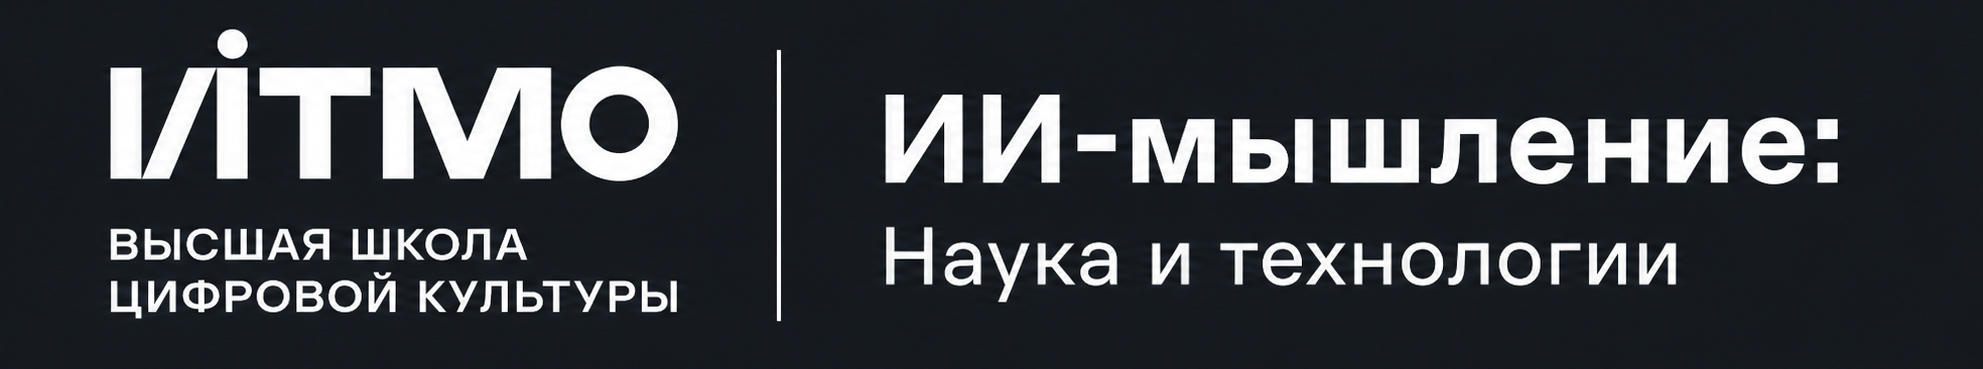

# Неделя 02. Механизм внимания (Attention) и позиционное кодирование (Базовый уровень)

## Информация
---

**Цель работы:** Реализовать с нуля scaled dot-product attention, причинную маску и KV-кеш, проверить каждый блок тестами и понять, как KV-кеш ускоряет пошаговую генерацию.


In [ ]:
# ruff: noqa: E402, F811
import sys
import subprocess

sys.modules['torchvision'] = None  # блокируем torchvision: конфликт версий с установленным torch


def print_ok(msg="Все проверки пройдены"):
    """
    Печатает зеленое сообщение об успешной проверке.

    msg : str
        Текст сообщения.
    """
    print(f"\033[92m[OK]\033[0m {msg}")


def print_error(msg=""):
    """
    Печатает красное сообщение об ошибке проверки.

    msg : str
        Текст сообщения.
    """
    print(f"\033[91m[ERROR]\033[0m {msg}")


""" for package in ("numpy", "torch", "matplotlib"):
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package]) """


In [ ]:
import math
import random
import time
from typing import List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print(f"PyTorch: {torch.__version__}")


# Задание 1. Scaled Dot-Product Attention — реализация с нуля

Механизм scaled dot-product attention вычисляет сходство между query и key, масштабирует его, применяет softmax и взвешивает векторы value.

Формула:
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

**Реализуйте:**
* Функцию `scaled_dot_product_attention`, которая возвращает выход внимания и матрицу весов.


In [ ]:
def scaled_dot_product_attention(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    mask: Optional[torch.Tensor] = None
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Вычисляет Scaled Dot-Product Attention.

    q : torch.Tensor
        Query тензор формы (batch, heads, seq_len_q, d_k).
    k : torch.Tensor
        Key тензор формы (batch, heads, seq_len_k, d_k).
    v : torch.Tensor
        Value тензор формы (batch, heads, seq_len_k, d_v).
    mask : torch.Tensor, optional
        Булева маска формы (seq_len_q, seq_len_k); False означает запрещенную позицию.

    Returns
    -------
    Tuple[torch.Tensor, torch.Tensor]
        output: результат внимания формы (batch, heads, seq_len_q, d_v),
        attn_weights: веса внимания формы (batch, heads, seq_len_q, seq_len_k).
    """
    # TODO: scores = Q K^T / sqrt(d_k), затем маска, softmax по последней оси и умножение на V
    d_k = q.size(-1)

    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    attn_weights = F.softmax(scores, dim=-1)

    output = torch.matmul(attn_weights, v)

    return output, attn_weights


In [ ]:
try:
    batch, heads, seq_len, d_k, d_v = 2, 3, 5, 16, 32
    q = torch.randn(batch, heads, seq_len, d_k)
    k = torch.randn(batch, heads, seq_len, d_k)
    v = torch.randn(batch, heads, seq_len, d_v)

    output, attn = scaled_dot_product_attention(q, k, v)
    assert output.shape == (batch, heads, seq_len, d_v), f"Неверная форма выхода: {output.shape}"
    assert attn.shape == (batch, heads, seq_len, seq_len), f"Неверная форма весов: {attn.shape}"
    assert torch.allclose(attn.sum(dim=-1), torch.ones(batch, heads, seq_len), atol=1e-5), \
        "Веса внимания по строкам должны суммироваться в 1"
    assert torch.allclose(output, attn @ v, atol=1e-5), "output должен равняться attn @ v"

    ref = F.scaled_dot_product_attention(q, k, v)
    assert torch.allclose(output, ref, atol=1e-5), "Результат расходится с F.scaled_dot_product_attention"

    mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool))
    _, attn_masked = scaled_dot_product_attention(q, k, v, mask=mask)
    assert attn_masked.triu(diagonal=1).abs().max() < 1e-6, "Запрещенные позиции маски должны получать нулевой вес"
    print_ok("scaled_dot_product_attention: все проверки пройдены")
except Exception as e:
    print_error(f"Тест scaled_dot_product_attention провален: {e}")


In [ ]:
# TODO: постройте веса внимания для случайных Q и K и для K, близкого к Q; сравните картины
torch.manual_seed(0)

B, H, L, D = 1, 1, 8, 16

q1 = torch.randn(B, H, L, D)
k1 = torch.randn(B, H, L, D)
v1 = torch.randn(B, H, L, D)

_, attn_random = scaled_dot_product_attention(q1, k1, v1)

q2 = torch.randn(B, H, L, D)
k2 = q2 + 0.1 * torch.randn(B, H, L, D)
v2 = torch.randn(B, H, L, D)

_, attn_close = scaled_dot_product_attention(q2, k2, v2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(attn_random[0, 0].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Q, K случайные и независимые")
axes[0].set_xlabel("key (позиция)")
axes[0].set_ylabel("query (позиция)")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(attn_close[0, 0].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("K близок к Q (K = Q + 0.1·шум)")
axes[1].set_xlabel("key (позиция)")
axes[1].set_ylabel("query (позиция)")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

> ***Вопрос на подумать***
>
> Почему веса внимания нормируются делителем $\sqrt{d_k}$? Что произойдет с softmax, если для больших $d_k$ этот делитель не применять?
>
> ***Ответ:*** Веса внимания делят на корень из размерности ключа, потому что при увеличении этой размерности скалярные произведения запросов и ключей становятся слишком большими по модулю. Без нормировки softmax получает очень большие значения и становится почти one-hot. Практически весь вес достаётся одному токену, а остальным около нуля. Из-за этого модель теряет способность распределять внимание между несколькими релевантными элементами. Кроме того, при вероятностях, близких к 0 или 1, градиенты softmax очень малы, поэтому обучение становится медленным и нестабильным. Деление на корень из размерности возвращает логиты к разумному масштабу и делает механизм внимания устойчивее.


# Задание 2. Causal Mask — причинная маска

В авторегрессионных генеративных моделях токен не должен видеть будущее. Причинная маска запрещает внимание к будущим позициям.

**Реализуйте:**
* Функцию `create_causal_mask`, которая возвращает булеву нижнетреугольную матрицу.


In [ ]:
def create_causal_mask(seq_len: int) -> torch.Tensor:
    """
    Создаёт причинную (causal) маску внимания для генерации.

    seq_len : int
        Длина последовательности токенов.

    Returns
    -------
    torch.Tensor
        Булева нижнетреугольная матрица формы (seq_len, seq_len);
        True разрешает внимание к позиции, False запрещает.
    """
    # TODO: нижнетреугольная матрица из единиц, приведенная к типу bool
    return torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool))

In [ ]:
try:
    seq_len = 6
    causal_mask = create_causal_mask(seq_len)
    expected = torch.tensor([[j <= i for j in range(seq_len)] for i in range(seq_len)])
    assert causal_mask.shape == (seq_len, seq_len), f"Неверная форма маски: {causal_mask.shape}"
    assert causal_mask.dtype == torch.bool, "Тип данных маски должен быть torch.bool"
    assert torch.equal(causal_mask, expected), "Маска должна разрешать внимание только к текущей и прошлым позициям"

    q = torch.randn(1, 1, seq_len, 8)
    k = torch.randn(1, 1, seq_len, 8)
    v = torch.randn(1, 1, seq_len, 8)
    out_1, attn = scaled_dot_product_attention(q, k, v, mask=causal_mask)
    assert torch.allclose(attn.sum(dim=-1), torch.ones(1, 1, seq_len), atol=1e-5), "Строки весов должны суммироваться в 1"
    assert attn.triu(diagonal=1).abs().max() < 1e-6, "Веса будущих позиций должны быть нулевыми"

    v_changed = v.clone()
    v_changed[:, :, 3:] += 10.0
    out_2, _ = scaled_dot_product_attention(q, k, v_changed, mask=causal_mask)
    assert torch.allclose(out_1[:, :, :3], out_2[:, :, :3], atol=1e-5), \
        "Выходы для ранних позиций не должны зависеть от будущих значений V"
    print_ok("create_causal_mask: все проверки пройдены")
except Exception as e:
    print_error(f"Тест create_causal_mask провален: {e}")


In [ ]:
# TODO: постройте маску причинного внимания и сравните bidirectional и causal веса на одних и тех же Q, K, V
torch.manual_seed(0)
L, D = 6, 16
q = torch.randn(1, 1, L, D)
k = torch.randn(1, 1, L, D)
v = torch.randn(1, 1, L, D)

_, attn_bi = scaled_dot_product_attention(q, k, v)

causal_mask = create_causal_mask(L)
_, attn_causal = scaled_dot_product_attention(q, k, v, mask=causal_mask)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(attn_bi[0, 0].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Bidirectional (без маски)")
axes[0].set_xlabel("key"); axes[0].set_ylabel("query")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(attn_causal[0, 0].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Causal (нижнетреугольная маска)")
axes[1].set_xlabel("key"); axes[1].set_ylabel("query")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

> ***Вопрос на подумать***
>
> Почему маска нужна при обучении на всей последовательности, а при пошаговой генерации с KV-кешем явная маска по сути не требуется?
>
> ***Ответ:*** При обучении на всей последовательности все токены обрабатываются одновременно, поэтому без причинной маски токен мог бы использовать информацию из будущих токенов, что привело бы к утечке данных и неправильному обучению. Маска запрещает каждому токену смотреть вперёд и заставляет модель предсказывать следующий токен только по уже известным предыдущим. При пошаговой генерации с KV-кешем на каждом шаге вычисляется только новый токен, а его запрос сравнивается исключительно с ключами и значениями уже сгенерированных прошлых токенов. Будущих токенов в кеше ещё нет, поэтому утечка информации вперёд физически невозможна. Следовательно, явная маска нужна в основном при параллельной обработке всей последовательности, а при инкрементальной генерации причинность обеспечивается самим порядком вычислений.


# Задание 3. KV-Cache — кеширование ключей и значений

При пошаговой генерации K и V для прошлых токенов не меняются, поэтому пересчитывать их на каждом шаге неэффективно. KV-cache хранит их и добавляет только новые.

**Реализуйте:**
* Методы `update`, `reset` и свойство `seq_len` класса `KVCache`;
* Функцию `attention_with_cache`, которая обновляет кеш и вычисляет внимание для нового токена.


In [ ]:
class KVCache:
    """
    Кеш ключей (K) и значений (V) для пошагового инференса.
    """

    def __init__(self):
        """
        Инициализация пустого KV-кеша.
        """
        self.k_cache = None
        self.v_cache = None

    def update(self, k_new: torch.Tensor, v_new: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Добавляет новые ключи и значения в кеш.

        k_new : torch.Tensor
            Новый тензор ключей формы (batch, n_heads, 1, d_k).
        v_new : torch.Tensor
            Новый тензор значений формы (batch, n_heads, 1, d_v).

        Returns
        -------
        Tuple[torch.Tensor, torch.Tensor]
            k_cache: полный накопленный тензор K,
            v_cache: полный накопленный тензор V.
        """
        # TODO: допишите k_new и v_new по оси длины (dim=-2) к кешу и верните накопленные тензоры
        if self.k_cache is None:
            self.k_cache = k_new
            self.v_cache = v_new
        else:
            self.k_cache = torch.cat([self.k_cache, k_new], dim=-2)
            self.v_cache = torch.cat([self.v_cache, v_new], dim=-2)
        return self.k_cache, self.v_cache

    def reset(self) -> None:
        """
        Сбрасывает закешированные значения.
        """
        # TODO: сбросьте оба кеша в None
        self.k_cache = None
        self.v_cache = None

    @property
    def seq_len(self) -> int:
        """
        Текущая длина закешированной последовательности токенов.
        """
        # TODO: верните длину закешированной последовательности, 0 если кеш пуст
        if self.k_cache is None:
            return 0
        return self.k_cache.size(-2)


In [ ]:
def attention_with_cache(
    q_new: torch.Tensor,
    k_new: torch.Tensor,
    v_new: torch.Tensor,
    cache: KVCache
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Вычисляет внимание для нового токена с использованием KV-кеша.

    q_new : torch.Tensor
        Query тензор нового токена формы (batch, n_heads, 1, d_k).
    k_new : torch.Tensor
        Key тензор нового токена формы (batch, n_heads, 1, d_k).
    v_new : torch.Tensor
        Value тензор нового токена формы (batch, n_heads, 1, d_v).
    cache : KVCache
        Объект KV-кеша.

    Returns
    -------
    Tuple[torch.Tensor, torch.Tensor]
        output: результат внимания формы (batch, n_heads, 1, d_v),
        attn_weights: веса внимания формы (batch, n_heads, 1, seq_len_cache).
    """
    # TODO: обновите кеш через cache.update и вычислите внимание для q_new по всему кешу
    k_full, v_full = cache.update(k_new, v_new)
    output, attn_weights = scaled_dot_product_attention(q_new, k_full, v_full)
    return output, attn_weights


In [ ]:
try:
    cache = KVCache()
    assert cache.seq_len == 0, "Начальная длина кеша должна быть 0"

    k_1 = torch.randn(1, 2, 1, 16)
    v_1 = torch.randn(1, 2, 1, 16)
    k_full, v_full = cache.update(k_1, v_1)
    assert cache.seq_len == 1, "После одного обновления длина кеша должна быть 1"
    assert k_full.shape == (1, 2, 1, 16), f"Неверная форма K: {k_full.shape}"

    cache.update(torch.randn(1, 2, 1, 16), torch.randn(1, 2, 1, 16))
    assert cache.seq_len == 2, "После двух обновлений длина кеша должна быть 2"
    cache.reset()
    assert cache.seq_len == 0, "После reset длина кеша должна быть 0"

    seq_len = 6
    q_all = torch.randn(1, 2, seq_len, 16)
    k_all = torch.randn(1, 2, seq_len, 16)
    v_all = torch.randn(1, 2, seq_len, 16)
    full_out, _ = scaled_dot_product_attention(q_all, k_all, v_all, mask=create_causal_mask(seq_len))

    cache = KVCache()
    for t in range(seq_len):
        out_t, weights_t = attention_with_cache(
            q_all[:, :, t:t + 1], k_all[:, :, t:t + 1], v_all[:, :, t:t + 1], cache
        )
        assert cache.seq_len == t + 1, f"Шаг {t}: длина кеша должна быть {t + 1}"
        assert out_t.shape == (1, 2, 1, 16), f"Шаг {t}: неверная форма выхода {out_t.shape}"
        assert torch.allclose(out_t, full_out[:, :, t:t + 1], atol=1e-5), \
            f"Шаг {t}: пошаговый выход с кешем не совпадает с полным causal-вниманием"
    print_ok("KVCache и attention_with_cache: все проверки пройдены")
except Exception as e:
    print_error(f"Тест KV-Cache провален: {e}")


In [ ]:
# TODO: сравните время генерации 20 токенов без кеша и с кешем, постройте график роста вычислений
torch.manual_seed(0)
L, D, H, B = 20, 32, 1, 1

q_all = torch.randn(B, H, L, D)
k_all = torch.randn(B, H, L, D)
v_all = torch.randn(B, H, L, D)

def generate_no_cache(steps):
    for t in range(1, steps + 1):
        _ = scaled_dot_product_attention(
            q_all[:, :, :t], k_all[:, :, :t], v_all[:, :, :t],
            mask=create_causal_mask(t)
        )

def generate_with_cache(steps):
    cache = KVCache()
    for t in range(steps):
        _ = attention_with_cache(
            q_all[:, :, t:t+1], k_all[:, :, t:t+1], v_all[:, :, t:t+1],
            cache
        )

generate_no_cache(5)
generate_with_cache(5)

t0 = time.perf_counter()
generate_no_cache(L)
t_no_cache = time.perf_counter() - t0

t0 = time.perf_counter()
generate_with_cache(L)
t_with_cache = time.perf_counter() - t0

print(f"Без кеша:  {t_no_cache*1000:.2f} ms")
print(f"С кешем:   {t_with_cache*1000:.2f} ms")
print(f"Ускорение: {t_no_cache / t_with_cache:.2f}x")

steps = list(range(1, L + 1))
times_no_cache = []
times_with_cache = []

for s in steps:
    t0 = time.perf_counter()
    generate_no_cache(s)
    times_no_cache.append((time.perf_counter() - t0) * 1000)

    t0 = time.perf_counter()
    generate_with_cache(s)
    times_with_cache.append((time.perf_counter() - t0) * 1000)

plt.figure(figsize=(9, 5))
plt.plot(steps, times_no_cache, marker="o", label="Без кеша (O(N²))")
plt.plot(steps, times_with_cache, marker="s", label="С кешем (O(N))")
plt.xlabel("Число сгенерированных токенов N")
plt.ylabel("Время, мс")
plt.title("Стоимость пошаговой генерации")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> ***Вопрос на подумать***
>
> Во сколько раз снижается вычислительная сложность генерации $N$-го токена при использовании KV-cache по сравнению с полным пересчетом? Какова цена KV-cache по памяти (VRAM)?
>
> ***Ответ:*** Использование KV-cache снижает вычислительную сложность генерации N-го токена примерно в N раз, т. е. пропорционально длине контекста, так как вместо полного повторного пересчета матриц для всех прошлых токенов модель вычисляет векторы только для одного текущего шага. Платой за это ускорение является линейный рост расхода VRAM, в которой сохраняются векторы ключей и значений для всей истории диалога. Точный объем кэша зависит от архитектуры и рассчитывается как удвоенное произведение количества слоев, KV-голов, размерности головы, длины контекста, размера батча и байт на один элемент.


## Что сдавать

1. Выполненный блокнот со всеми ячейками.
2. Ответы на вопросы «на подумать» в каждом задании.


## Полезные материалы и ссылки

- [Attention Is All You Need (Vaswani et al., 2017)](https://arxiv.org/abs/1706.03762)
- [RoFormer: Rotary Position Embedding (Su et al., 2021)](https://arxiv.org/abs/2104.09864)
- [Hugging Face LLM tutorial on KV-Cache](https://huggingface.co/docs/transformers/llm_tutorial)
- [Illustrated Transformer by Jay Alammar](https://jalammar.github.io/illustrated-transformer/)
